In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [73]:
plt.rc('font', size=14)
plt.rc('axes',labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [74]:
np.random.seed(42)

m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

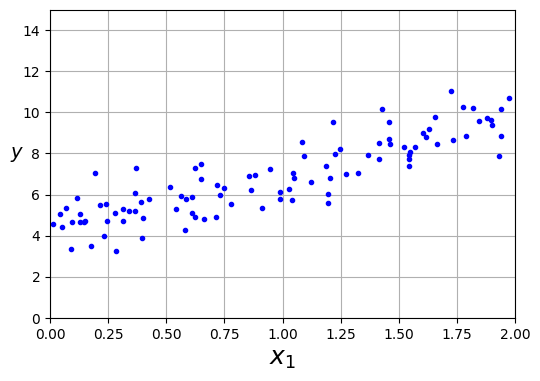

In [75]:
plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0)
plt.axis([0,2,0,15])
plt.grid()

In [76]:
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])

result = matrix_a @ matrix_b
result1=np.dot(matrix_a,matrix_b)
print('Matrix A:')
print(matrix_a)
print('\nMatrix B:')
print(matrix_b)
print('\nResult of Matrix Multiplication (A @ B):')
print(result1)

Matrix A:
[[1 2]
 [3 4]]

Matrix B:
[[5 6]
 [7 8]]

Result of Matrix Multiplication (A @ B):
[[19 22]
 [43 50]]


In [77]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)

theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

In [78]:
theta_best

array([[4.21509616],
       [2.77011339]])

In [79]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new)
X_new_b

array([[1., 0.],
       [1., 2.]])

In [80]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b.dot(theta_best)
y_predict

array([[4.21509616],
       [9.75532293]])

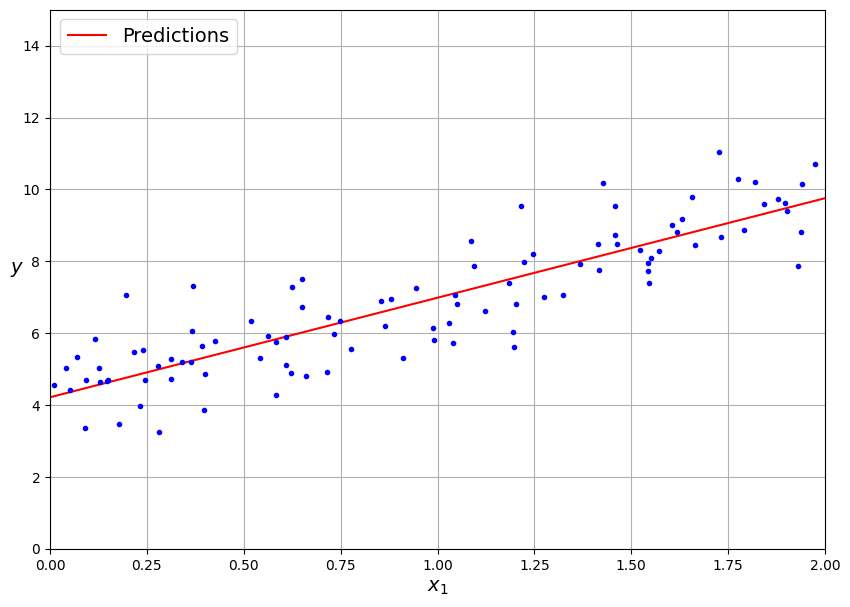

In [81]:
plt.figure(figsize=(10, 7))
plt.plot(X_new, y_predict,'r-', label='Predictions')
plt.plot(X,y,'b.')
plt.xlabel('$x_1$', rotation=0)
plt.ylabel('$y$', rotation=0)
plt.axis([0,2,0,15])
plt.grid()
plt.legend(loc='upper left')
plt.show()

In [82]:
X.shape, X.T.shape

((100, 1), (1, 100))

In [83]:
def linreg(X,y):
  return np.linalg.inv(X.T @ X) @ X.T @ y
print(linreg(X_b,y))

[[4.21509616]
 [2.77011339]]


In [84]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X,y)
lin_reg.intercept_, lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

In [85]:
np.random.seed(42)
eta = 0.1
m=len(X_b)
theta = np.random.randn(2,1)
n_epochs = 1000
for epoch in range(n_epochs):
  for iteration in range(m):
    random_index = np.random.randint(m)
    xi = X_b[random_index:random_index+1]
    yi = y[random_index:random_index+1]
    gradients = 2 * xi.T @ (xi @ theta - yi)
    theta = theta - eta * gradients

In [86]:
theta

array([[4.17686315],
       [2.85986577]])

In [87]:
from sklearn.linear_model import SGDRegressor
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.1,n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())

SGDRegressor(eta0=0.1, n_iter_no_change=100, penalty=None, random_state=42)

In [88]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.22612746]), array([2.79035392]))

In [89]:
from math import ceil
n_epochs = 50
eta=0.1
m=len(X_b)
minibatch_size=20
n_batches_per_epoch = ceil(m / minibatch_size)

np.random.seed(42)
theta=np.random.randn(2,1)

for epoch in range(n_epochs):
  shuffled_indices = np.random.permutation(m)
  X_b_shuffled = X_b[shuffled_indices]
  y_shuffled = y[shuffled_indices]
  for iteration in range(0,n_batches_per_epoch):
    idx = iteration * minibatch_size
    xi=X_b_shuffled[idx:idx+minibatch_size]
    yi=y_shuffled[idx:idx+minibatch_size]
    gradients = 2/minibatch_size * xi.T @ (xi @ theta - yi)
    theta = theta - eta * gradients

In [90]:
np.random.permutation(m)

array([84, 29,  4, 85, 40, 69,  0, 46, 89, 82, 22, 74, 33, 73, 91, 79, 28,
       35,  2, 51, 32, 90,  7, 42, 44, 71, 13, 53, 27, 36, 41, 88,  5, 58,
       49, 57, 24, 99, 60, 48, 50, 34,  6, 18, 95, 97, 11, 76, 15, 80, 93,
       20, 26, 25, 19, 67, 72, 31, 66, 70, 38, 75, 62, 77, 65, 14, 78, 83,
       17, 47, 12, 92,  8, 55, 52, 54, 56, 64, 16, 98, 59, 43, 23, 39,  9,
       96, 68, 61, 45, 10, 30,  1, 21, 86, 87, 37, 63, 81, 94,  3])

In [91]:
theta

array([[4.22023943],
       [2.7704472 ]])

### Polynominal regression

In [92]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m,1)-3
y=0.5 *X **2+X+2+np.random.randn(m,1)

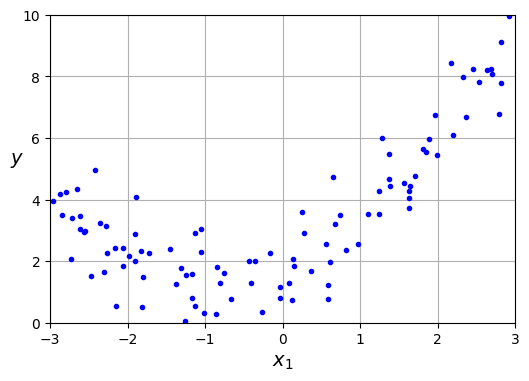

In [93]:
plt.figure(figsize=(6,4))
plt.plot(X,y,'b.')
plt.xlabel('$x_1$', rotation=0)
plt.ylabel('$y$', rotation=0)
plt.axis([-3,3,0,10])
plt.grid()
plt.show()

In [94]:
lin_reg.fit(X,y)
predictions = lin_reg.predict([[-3],[3]])
predictions

array([[1.03315352],
       [6.09487734]])

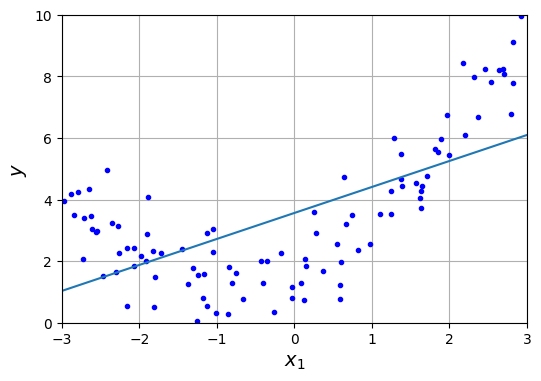

In [95]:
plt.figure(figsize=(6,4))
plt.plot(X,y,'b.')
plt.plot([-3,3],predictions)
plt.xlabel('$x_1$')
plt.ylabel('$y$')
plt.axis([-3,3,0,10])
plt.grid()
plt.show()

In [96]:
lin_reg.score(X,y)

0.42600823789139797

In [97]:
from sklearn.preprocessing import PolynomialFeatures

In [98]:
poly_features = PolynomialFeatures(degree=2,include_bias=False)
X_poly = poly_features.fit_transform(X)
X[0]

array([-0.75275929])

In [99]:
X_poly[0]

array([-0.75275929,  0.56664654])

In [100]:
lin_reg.fit(X_poly,y)
lin_reg.intercept_ , lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

In [101]:
model=lin_reg.fit(X_poly,y)
poly_predict = model.predict

In [102]:
X.shape

(100, 1)

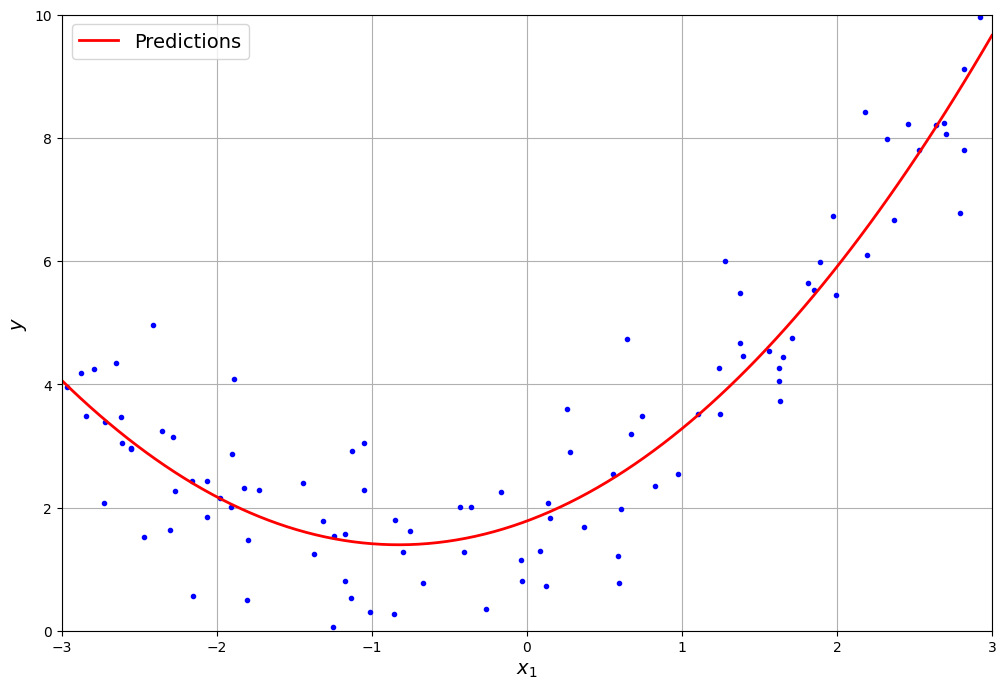

In [103]:
X_new=np.linspace(-3,3,100).reshape(100,1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(12,8))
plt.plot(X,y,'b.')
plt.plot(X_new,y_new,'r-',linewidth=2,label='Predictions')
plt.xlabel('$x_1$')
plt.ylabel('$y$')
plt.axis([-3,3,0,10])
plt.grid()
plt.legend(loc='upper left')
plt.show()

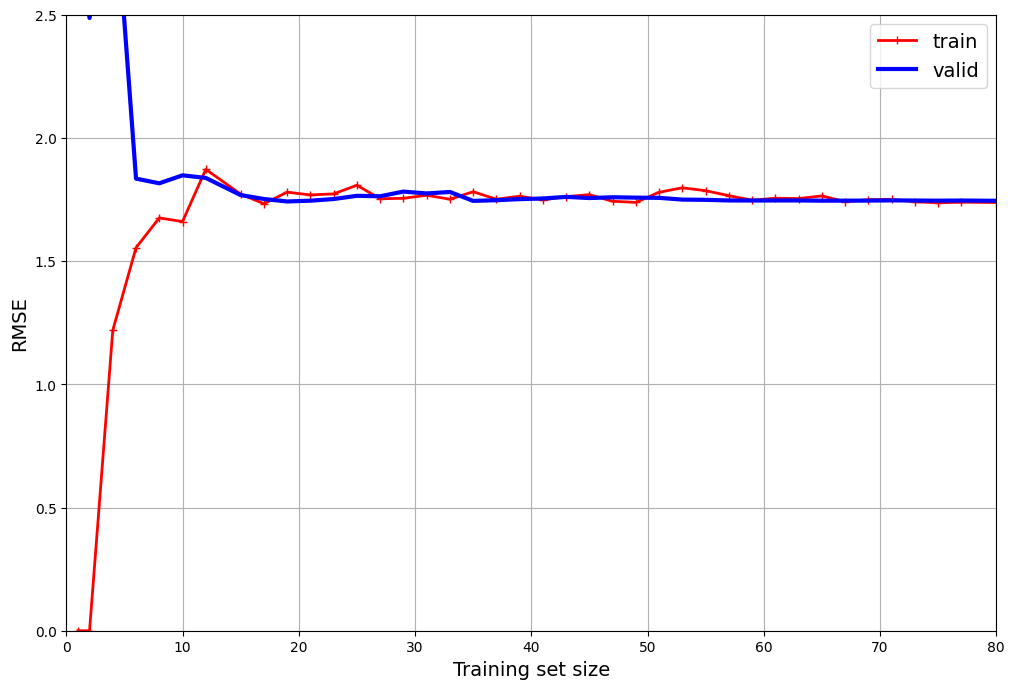

In [104]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring='neg_root_mean_squared_error'
)

train_errors = -train_scores.mean(axis = 1)
valid_errors = -valid_scores.mean(axis = 1)

plt.figure(figsize = (12, 8))
plt.plot(train_sizes, train_errors, 'r-+', linewidth = 2, label='train')
plt.plot(train_sizes, valid_errors, 'b-', linewidth = 3, label='valid')

plt.xlabel('Training set size')
plt.ylabel('RMSE')
plt.grid()
plt.legend(loc='upper right')
plt.axis([0, 80, 0, 2.5])

plt.show()

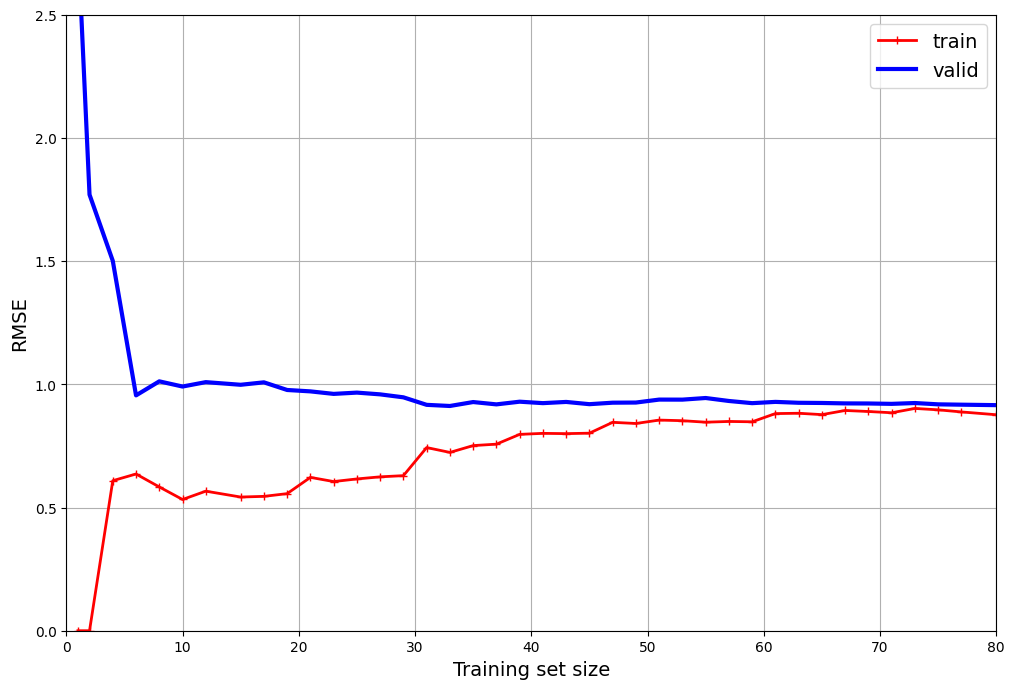

In [105]:
from sklearn.pipeline import make_pipeline

polynominal_regression = make_pipeline(
    PolynomialFeatures(2, include_bias=False),
    LinearRegression()
)

train_sizes, train_scores, valid_scores = learning_curve(
    polynominal_regression, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring='neg_root_mean_squared_error'
)

train_errors = -train_scores.mean(axis =1)
valid_errors = -valid_scores.mean(axis = 1)

plt.figure(figsize = (12, 8))
plt.plot(train_sizes, train_errors, 'r-+', linewidth = 2, label='train')
plt.plot(train_sizes, valid_errors, 'b-', linewidth = 3, label='valid')

plt.xlabel('Training set size')
plt.ylabel('RMSE')
plt.grid()
plt.legend(loc='upper right')
plt.axis([0, 80, 0, 2.5])
plt.show()

# Regularized linear models

In [106]:
np.random.seed(42)
m=20
X = 3* np.random.rand(m,1)
y=1 + 0.5 * X + np.random.randn(m,1)/1.5
X_new = np.linspace(0, 3 , 100).reshape(100,1)

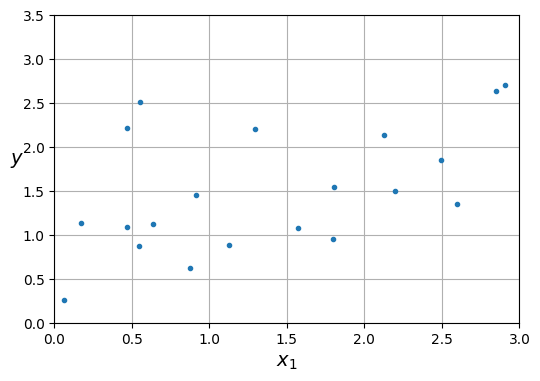

In [107]:
plt.figure(figsize=(6,4))
plt.plot(X,y,'.')
plt.xlabel('$x_1$')
plt.ylabel('$y$',rotation=0)
plt.axis([0,3,0,3.5])
plt.grid()
plt.show()

In [109]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha=0.1, solver='cholesky')
ridge_reg.fit(X,y)
ridge_reg.predict([[1.5]])

array([1.55325833])

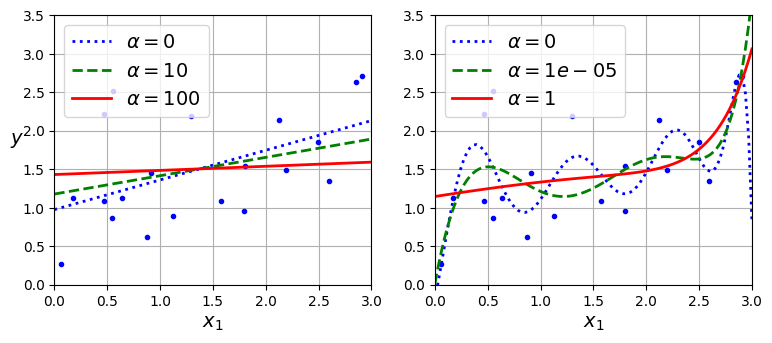

In [111]:
from sklearn.preprocessing import StandardScaler

def plot_model(model_class, polynomial, alphas, **model_kwargs):
  plt.plot(X, y , 'b.', linewidth = 3)
  for alpha, style, in zip(alphas, ('b:', 'g--', 'r-')):
    if alpha > 0 :
      model = model_class(alpha, **model_kwargs)
    else:
      model = LinearRegression()
    if polynomial:
      model = make_pipeline(
          PolynomialFeatures(degree = 10, include_bias= False),
          StandardScaler(),
          model
      )
    model.fit(X, y)
    y_new_regul = model.predict(X_new)
    plt.plot(X_new, y_new_regul, style, linewidth = 2,
             label=fr'$\alpha = {alpha}$')
  plt.legend(loc='upper left')
  plt.xlabel('$x_1$')
  plt.axis([0, 3, 0, 3.5])
  plt.grid()


plt.figure(figsize=(9, 3.5))
plt.subplot(121)
plot_model(Ridge, polynomial=False, alphas=(0, 10, 100), random_state = 42)
plt.ylabel('$y$', rotation= 0)
plt.subplot(122)
plot_model(Ridge, polynomial=True, alphas=(0, 10**-5, 1), random_state=42)
plt.show()

In [112]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(penalty= 'l2',
                       max_iter = 1000, eta0=0.01, random_state=42)
sgd_reg.fit(X, y.ravel())
sgd_reg.predict([[1.5]])

array([1.47012588])

In [113]:
ridge_reg2=Ridge(alpha=0.011,solver='sag')
ridge_reg2.fit(X,y)
ridge_reg2.predict([[1.5]])

array([1.55354702])

In [118]:
alpha = 0.1
A = np.array([[0., 0.], [0., 1.]])
X_b = np.c_[np.ones(m), X]
np.linalg.inv(X_b.T @ X_b + alpha * A) @ X_b.T @ y

array([[0.97898394],
       [0.3828496 ]])

In [119]:
ridge_reg2.intercept_, ridge_reg2.coef_

(array([0.97586003]), array([0.38512466]))

# Lasso Regression (L1)


In [120]:
from sklearn.linear_model import Lasso

lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X, y)
lasso_reg.predict([[1.5]])

array([1.53788174])

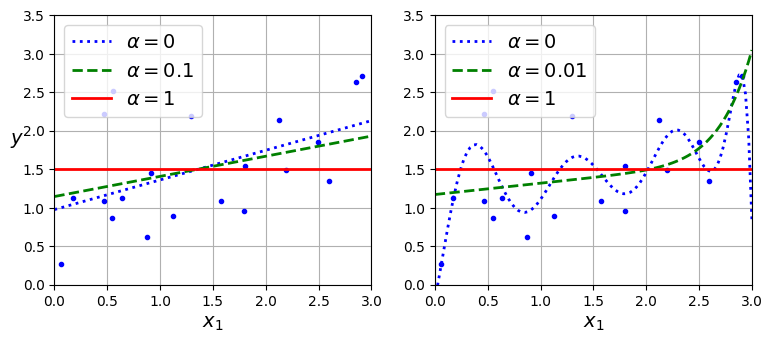

In [124]:
plt.figure(figsize= (9, 3.5))
plt.subplot(121)
plot_model(Lasso, polynomial= False, alphas=(0, 0.1, 1) , random_state=42)
plt.ylabel('$y$', rotation=0)
plt.subplot(122)
plot_model(Lasso, polynomial= True, alphas=(0, 1e-2m, 1), random_state=42)
plt.show()